In [1]:
"""  
we are building a state graph hving 2 main nodes:

    1 . Agent : will decide to use tool or not
    2. Tool extractor: execute the tool and feed the result to agent

""";

In [3]:
import os
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, END, START
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import ToolNode
from langchain_core.messages import BaseMessage
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph.message import add_messages

In [4]:
class State(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [5]:
model = ChatOpenAI(
    model = 'gemini-2.5-flash-lite',
    base_url= 'https://openrouter.ai/api/v1',
    api_key= os.getenv("OPENROUTER_API_KEY"),
    temperature= 0.5,
)

In [6]:
from dotenv import load_dotenv
load_dotenv()

True

In [9]:
import warnings
warnings.filterwarnings('ignore')

In [10]:
# setup the tool
search_tool = TavilySearchResults(max_results= 2)

In [11]:
tools = [search_tool]
tool_node = ToolNode(tools)

In [12]:
llm_with_tools = model.bind_tools(tools)

In [13]:
# graph node functions

In [14]:
def call_model(state: State) -> State:

    response = llm_with_tools.invoke(state['messages'])

    return {"messages": [response]}

In [16]:
# need router (this is not a tool and wont change the state)
# it will check the last message and will return the name of the next node

def should_continue(state: State):

    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tools"

    return END

In [17]:
# build th graph

In [ ]:
workflow = StateGraph(State)

workflow.add_node("agent", call_model)
workflow.add_node('tools', tool_node)

workflow.set_entry_point('agent') # this is same as START -> NODE
workflow.add_conditional_edges('agent', should_continue)
workflow.add_edge('tools', 'agent')

In [19]:
app = workflow.compile()

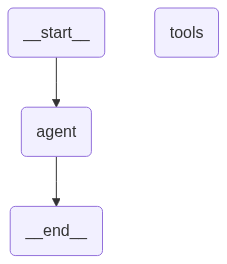

In [20]:
app

In [21]:
# execute 

In [22]:
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage

In [23]:
system_msg = SystemMessage(content = (
    "you are a helpful assistant with access to real time web search tool"
    "if you dont know the answer (like wwather or current news)"
    "always use the search tool. DO not say you cannot help, use tool instead"
))

In [25]:
inputs = {
    "messages": [system_msg, HumanMessage(content = "why the ai bubble is bursting now in nov 2026. give top 3 reasons")]
}

In [26]:
for output in app.stream(inputs):
    print(output, "\n \n")

{'agent': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 138, 'total_tokens': 171, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 2.7e-05, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 2.7e-05, 'upstream_inference_prompt_cost': 1.38e-05, 'upstream_inference_completions_cost': 1.32e-05}}, 'model_provider': 'openai', 'model_name': 'google/gemini-2.5-flash-lite', 'system_fingerprint': None, 'id': 'gen-1794640319-vcitqgFbT1KIzCBV0qzC', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1d8e6-117f-77d1-91d7-d3cf293fcd41-0', tool_calls=[{'na

In [27]:
result = app.invoke(inputs)
print(result['messages'][-1].content)

The AI bubble is predicted to burst in November 2026 due to a confluence of factors:

1.  **Aggressive Valuations and Market Correction:** The stock market, particularly growth stocks heavily invested in AI (like Nvidia, Broadcom, and Palantir), is trading at historically high valuations. A significant market correction could disproportionately impact these AI-centric companies.

2.  **Mounting Competitive Pressures:** While demand for AI infrastructure (like GPUs) is high, many companies are struggling to optimize this technology or achieve a positive return on their investment. Increased competition, including the development of alternative chips and solutions, could erode the market share and pricing power of current AI leaders.

3.  **Circular Investment and Financing Concerns:** Similar to the dot-com bubble, there are concerns about a circular flow of investments artificially inflating stock values. Furthermore, hyperscalers are increasingly using debt, including long-dated bonds